# Using VAEAC for Video Prediction and camera motion prediction

In [1]:
import argparse
import os.path

import torch
import numpy as np
from torch import nn,optim
from videovae import VAEs
from torch import nn
from torch.utils.data import DataLoader  #Gives easier data management by creating mini batches etc.
from tqdm import tqdm
import matplotlib.pyplot as plt

/home/xu/xu/mmVAEAC_for_mobile_robot/mmVAEAC/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VAEs.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='./datasets/livingroom/')
parser.add_argument('--sequence_length', type=int, default=16)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=30)
args = parser.parse_args(args=[])
squence_length = 16
half_seq_len = int(squence_length/2)

cuda


## 1.Load the Datasets

### mobileRobo Dataset

In [3]:
from datasets.video_dataset import VideoDataset
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

metadata exists in: ./datasets/livingroom/train/metadata_16.pkl
metadata exists in: ./datasets/livingroom/test/metadata_16.pkl


## 2.Build the pretrained model

### 2.1 Build the proposal network, prior network and generative network

In [4]:
from videovae.pretrained_VAEAC import GaussianLoss, MobileNetDecoder, MobileNetEncoder
reonstruction_log_prob = GaussianLoss()
mobilenet_enc_proposal = MobileNetEncoder(96)
mobilenet_enc_prior = MobileNetEncoder(96)

# improve train computational stability by dividing the loss by this scale factor right before backpropagation
vlb_scale_factor = 64 ** 2 * 16

MLP_network_proposal = nn.Sequential(
    nn.Linear(1000, 1024)
)

MLP_network_prior = nn.Sequential(
    nn.Linear(1000, 1024)
)

MLP_network_vid = nn.Sequential(
    nn.Linear(512, 1024),
    
    nn.Linear(1024, 2048),
)

generative_network = MobileNetDecoder(96)


### 2.3 Load the pretrained checkpoint

In [5]:
from videovae.pretrained_VAEAC import VAEAC
MobileNet_pretrain = VAEAC(
    reonstruction_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
                 MLP_network_proposal, MLP_network_prior, MLP_network_vid, generative_network,
).to(DEVICE)
# model = nn.DataParallel(model)
modelData = './checkpoints/pretrained_mobilenet/600e_seg_4_2.pth.tar'
MobileNet_pretrain.load_state_dict(torch.load(modelData)['model_state_dict'])

<All keys matched successfully>

## 3.Build the mmVAEAC

In [6]:
reonstruction_log_prob = GaussianLoss()
mobilenet_enc_proposal = MobileNet_pretrain.mobilenet_enc_proposal
mobilenet_enc_prior = MobileNet_pretrain.mobilenet_enc_prior

# improve train computational stability by dividing the loss by this scale factor right before backpropagation
vlb_scale_factor = 64 ** 2 * 16

input_mot_channel = squence_length*4
mot_proposal_network = nn.Sequential(
    nn.Linear(input_mot_channel,input_mot_channel),
    nn.ReLU(),
    nn.Linear(input_mot_channel,128),
    nn.ReLU(),
    nn.Linear(128,256),
)

mot_prior_network = nn.Sequential(
    nn.Linear(input_mot_channel,input_mot_channel),
    nn.ReLU(),
    nn.Linear(input_mot_channel,128),
    nn.ReLU(),
    nn.Linear(128,256),
)

MLP_network_proposal = nn.Sequential(
    nn.Linear(1000 + 256, 1024),
    nn.Linear(1024, 1024),
)

MLP_network_prior = nn.Sequential(
    nn.Linear(1000 + 256, 1024),
    nn.Linear(1024, 1024),
)

MLP_network_vid = nn.Sequential(
    nn.Linear(512, 1024),
    nn.Linear(1024, 2048),

)

mot_generative_network = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 32),
    # nn.Sigmoid()
)

mobilenet_generative_network = MobileNet_pretrain.generative_network


## 4.Train the model

### 4.1 Continue from the checkpoint

In [7]:
from videovae.mmVAEAC import mmVAEAC
batch_size = args.batch_size
eval_losses = []
validation_iwae = []
checkpoint_path = os.path.join('./checkpoints/pretrained_mmVAEAC/')


model = mmVAEAC(
    reonstruction_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
    mot_proposal_network, mot_prior_network, MLP_network_proposal, MLP_network_prior, MLP_network_vid, mot_generative_network, mobilenet_generative_network
).to(DEVICE)

# 加载模型和权重

modelData = './checkpoints/pretrained_mmVAEAC/lvr_go3_60e.pth.tar'
checkpoint = torch.load(modelData)
model.load_state_dict(checkpoint['model_state_dict'])


<All keys matched successfully>

In [ ]:
from torch.utils.tensorboard import SummaryWriter  
from videovae.utils import extend_batch, extend_motion
from videovae.mmVAEAC import VideoFixedSequenceGenerator

mask_generator = VideoFixedSequenceGenerator()
optimizer = optim.Adam(model.parameters(), lr=args.LR_RATE)

#start Training
for epoch in range(args.NUM_EPOCHS):
    vlb_losses = []
    recon_losses = []
    KL_losses = []
    pr_losses = []
    model.train()
    loop = tqdm(dataloader_train)
    for x in loop:
        loop.set_description(f"Epoch {epoch}")

        batch, motion = dict.values(x)
         # (BCTHW)  
        batch = batch.to(DEVICE)
        motion = motion.permute(0,2,1).to(DEVICE)
        # print(motion.shape)
        # print(motion.mean(dim=4).mean(dim=3))
        batch = extend_batch(batch, dataloader_train, batch_size)
        motion = extend_motion(motion, dataloader_train, batch_size)
        mask_batch = mask_generator(batch)
        mask_motion = mask_generator(motion)
        # print(mask_motion.shape)
        # Make the shape of motion be the same with video
        if (motion.shape[0]!= args.batch_size):
            # print(1)
            continue
        # print(batch.shape, motion.shape)

        optimizer.zero_grad()
        recon_loss, kl_div, pr_loss = model.batch_vlb(batch, motion, mask_batch, mask_motion)
        recon_loss, kl_div, pr_loss = recon_loss, kl_div.mean()/vlb_scale_factor, pr_loss.mean()/ vlb_scale_factor 
        vlb = - recon_loss - kl_div + pr_loss
        loss = - vlb
        
        loss.backward()
        optimizer.step()

        loop.set_postfix(vlbloss=loss.item(), recon_loss=recon_loss.item(), kl_div=kl_div.item(), pr_loss=pr_loss.item())

    if ((epoch+1) % 5 == 0):
        torch.save({'model_state_dict': model.state_dict()}, checkpoint_path + '/cp_epoch_basetest'  + str(epoch+1) + '.pth.tar')

    writer = SummaryWriter('./log/mmVAEAC_megarover/')
    writer.add_scalar('Loss', loss.item(), epoch)
    writer.add_scalar('Recon_loss', recon_loss.item(), epoch)
    writer.add_scalar('kl_loss', kl_div.item(), epoch)

# Save the last checkpoint
torch.save({'model_state_dict': model.state_dict()}, checkpoint_path + '/m'  + str('%2f' % loss) + '.pth.tar')
# torch.save(model, checkpoint_path + '/m'  + str('%2f' % loss) + '.pth.tar')

## 5.Test the model

### Load a checkpoint

In [8]:
# load the mmVAEAC pretrained model
model = mmVAEAC(
    reonstruction_log_prob, mobilenet_enc_proposal, mobilenet_enc_prior,
    mot_proposal_network, mot_prior_network, MLP_network_proposal, MLP_network_prior, MLP_network_vid, mot_generative_network, mobilenet_generative_network
).to(DEVICE)

modelData = './checkpoints/pretrained_mmVAEAC/lvr_go3_60e.pth.tar'  

# 加载模型和权重
checkpoint = torch.load(modelData)
model.load_state_dict(checkpoint['model_state_dict'])

<All keys matched successfully>

### 4.1 The original input

In [10]:
valid_dataset = Dataset(args.data_path, args.sequence_length, train=True, resolution=args.resolution)

metadata exists in: ./datasets/livingroom/train/metadata_16.pkl


[ 51.   51.   51.   51.   51.   51.   51.   51.   51.   51.   51.   25.5
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  102.  102.   51.   76.5  51.
  51.  102.   76.5 102.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.   25.5  51.   51.   51.   51.   51.
  51.    0.   51.   51. ]
torch.Size([16, 64, 64, 3])
li:0.167 ang:0.000
li:0.195 ang:0.000
li:0.212 ang:0.000
li:0.214 ang:0.000
li:0.228 ang:-0.100
li:0.190 ang:-0.400
li:0.147 ang:-0.100
li:0.185 ang:-0.100


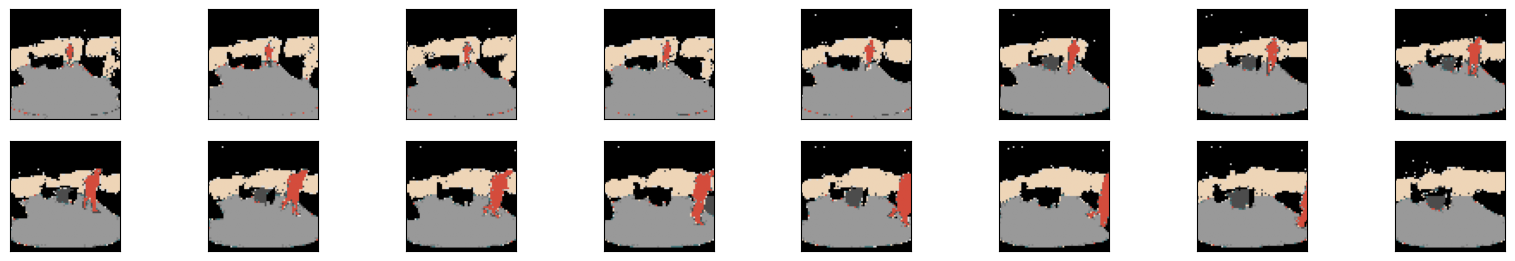

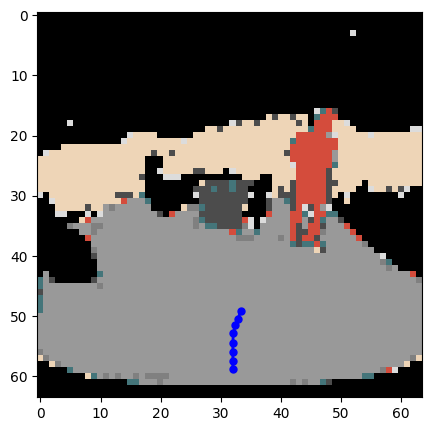

In [13]:
from videovae.utils import gray2color
from visual_utils import save_video
camera_actions =[]
fig = plt.figure(figsize=(20, 10))
im_list = []
im_all = []
scale = 0.25
count = 0
step = 3
last_motion = 'stop'
idx = 560
# 100, 400, 560
linear_gt = []
angle_gt = []

with torch.no_grad():
    # Load the batch and motion
    batch = valid_dataset[idx]
    batch, motion = dict.values(batch)
    motion = motion.permute(1,0).to(DEVICE)
    batch = batch.reshape(1,squence_length,64,64,9).to(DEVICE)
    # transfer one-hot encoding to gray scale image
    batch_rgb = torch.argmax(batch, 4)
    C, T, H, W = batch_rgb.shape
    # (C,T,H,W) --> (T,H,W,C)
    video_batch = torch.concat((batch_rgb,batch_rgb,batch_rgb),0)
    
    # video saving
    batch_rgb = batch_rgb.squeeze().cpu().detach().numpy()
    save_video('origin.mp4',video_batch.reshape(1,3,squence_length,64,64),5)
    
    dec_rgb = gray2color(batch.squeeze().permute(0,3,1,2))
    dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
    print(dec_rgb.shape)
    # The ground-truth unobserved actions (gt robot actions)
    for t in range(squence_length):
        if (t >= half_seq_len):            
            x = float(motion[t,0].mean())
            z = float(motion[t,1].mean())
            linear_gt.append(x)
            angle_gt.append(z)
            print('li:%.3f'%x,'ang:%.3f'%z)
    
    # Visualization of full information video inputs and gt robot actions
    for t in range(squence_length):
        im = torch.tensor(dec_rgb[t:t+1,:,:])
        im = im.view(H, W, 3)
        ax = fig.add_subplot(6, int(squence_length/2), int(squence_length/2)+t+1, xticks=[], yticks=[])
        if t==int(squence_length/2):
            map_x = 60 - 10*torch.cumsum(torch.tensor(linear_gt[::int(squence_length/16)]), dim=0)*np.cos(np.pi/4)
            map_z = 32 - torch.cumsum(torch.cumsum(torch.tensor(angle_gt[::int(squence_length/16)]), dim=0),dim=0)*np.cos(np.pi/4)
        ax.imshow(im[:,:],'gray')   

    fig1 = plt.figure(figsize=(20, 5))
    plt.plot(map_z.tolist(), map_x.tolist(), color='b', marker='o', linestyle='-',linewidth=2,markersize=5)
    im = torch.tensor(dec_rgb[half_seq_len-1,:,:]).view(H,W,3)
    plt.imshow(im, 'gray')

    

### 4.2 Generate the Sample

torch.Size([1, 18, 16, 64, 64])
li:0.183 ang:-0.046
li:0.183 ang:-0.088
li:0.179 ang:-0.099
li:0.191 ang:-0.090
li:0.171 ang:-0.145
li:0.175 ang:-0.242
li:0.160 ang:-0.198
li:0.169 ang:-0.192


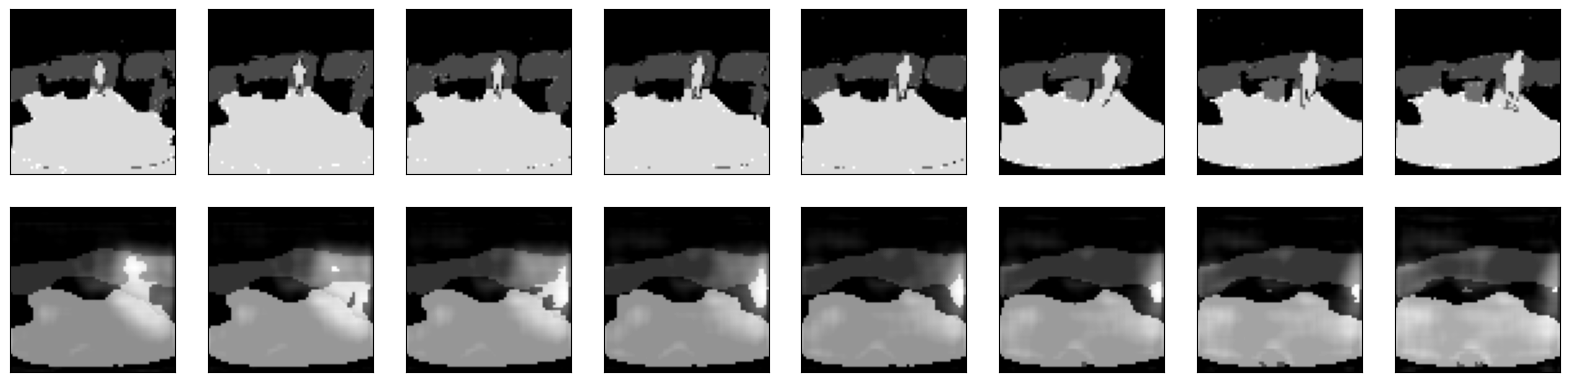

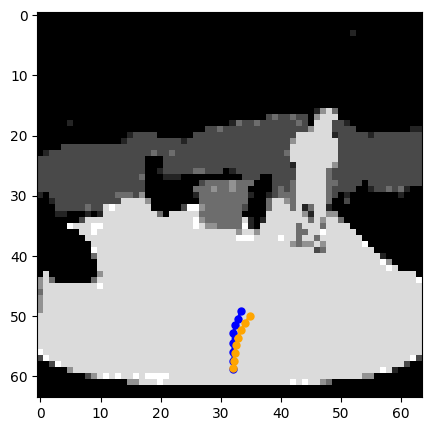

In [16]:
from videovae.pretrained_VAEAC import sampler
model.eval()
fig = plt.figure(figsize=(20, 15))
im_list = []
im_all = []
count = 0
camera_actions = []
linear_pd = []
angle_pd = []
with torch.no_grad():
    # actions shape: (1,16,2)
    # video shape: (1,16,64,64,9)
    # Generate masks for video and actions
    mot = motion.reshape(1,squence_length,2)
    mask_batch = mask_generator(batch).to(DEVICE)
    mask_motion = mask_generator(mot)

    # Reconstruct the unobserved features
    rec_params_vid, rec_params_mot = model.generate_samples_params(batch, mot, mask_batch, mask_motion)
    print(rec_params_vid.shape)
    img_samples = sampler(rec_params_vid)
    mot_samples = rec_params_mot.reshape(squence_length,2)

    # Preprocess for visualization (8 observed frames + 8 reconstructed frames)
    model_input = batch.permute(0,4,1,2,3).to(DEVICE)
    mask = mask_batch.permute(0,4,1,2,3)
    model_input[mask.byte()] = 0
    img_samples[1-mask.byte()] = 0
    img_samples += model_input
    video_clip = img_samples

    # Extract the channels presenting the intensity map of Human beings and the floor
    human_clip = img_samples[:,5]
    floor_clip = img_samples[:,6]

    predict_motion = mot_samples
    dec_vid = video_clip

    video_clip = torch.argmax(video_clip, 1)

    # Visualize the Human intensity
    C, T, H, W = video_clip.shape
    vid_clip = video_clip + human_clip

    # Save the video
    video_batch = torch.concat((vid_clip,vid_clip,vid_clip),0)
    save_video('demo.mp4',video_batch.reshape(1,3,squence_length,64,64),5)

    # (C,T,H,W) --> (T,H,W,C)
    video_clip = video_clip.permute(1,2,3,0).squeeze().cpu().detach().numpy()
    human_clip = human_clip.squeeze().cpu().detach().numpy()
    floor_clip = floor_clip.squeeze().cpu().detach().numpy()
    human_clip_img = human_clip
    video_clip = video_clip + 1*human_clip_img
    
    # The reconstructed robot actions
    for t in range(squence_length):
        if (t >= half_seq_len):
            # print(motion.shape)
            x = float(predict_motion[t,0])
            z = float(predict_motion[t,1]-0.5)
            linear_pd.append(x)
            angle_pd.append(z)
            print('li:%.3f'%x,'ang:%.3f'%z)
   
    # Visualization of reconstructed intensity maps and robot actions    
    for t in range(squence_length):
        im = torch.tensor(video_clip[t:t+1,:,:])
        im = im.view(H, W, C)
        # Calculate the human presence intensity
        if (t >= half_seq_len):
            sort_human_occur = sorted(human_clip[t].flatten(),reverse=True)
            sort_floor_occur = sorted(floor_clip[t].flatten(),reverse=True)
            mean_human_occur = np.array(sort_human_occur[:100]).mean()/6
            mean_floor_occur = np.array(sort_floor_occur[:50]).mean()
            prob_human = mean_human_occur/mean_floor_occur
    
        if t==int(squence_length/2):
            map_x_pd = 60 - 10*torch.cumsum(torch.tensor(linear_pd[::int(squence_length/16)]), dim=0)*np.cos(np.pi/4)
            map_z_pd = 32 - torch.cumsum(torch.cumsum(torch.tensor(angle_pd[::int(squence_length/16)]), dim=0),dim=0)*np.cos(np.pi/4)
        ax = fig.add_subplot(6, int(squence_length/2), int(squence_length/2)+t+1, xticks=[], yticks=[])
        ax.imshow(im[:,:,:3],'gray')  

    fig1 = plt.figure(figsize=(20, 5))
    plt.plot(map_z.tolist(), map_x.tolist(), color='b',marker='o', linestyle='-',linewidth=2,markersize=5)
    plt.plot(map_z_pd.tolist(), map_x_pd.tolist(), color='orange',marker='o', linestyle='-',linewidth=2,markersize=5)
    im = torch.tensor(video_clip[half_seq_len-1,:,:]).view(H,W,C)
    plt.imshow(im, 'gray')


torch.Size([1, 9, 16, 64, 64])
[ 51.   51.   51.   51.   51.   51.   51.   51.   51.   51.   51.   25.5
   0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  102.  102.   51.   76.5  51.
  51.  102.   76.5 102.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.   25.5  51.   51.   51.   51.   51.
  51.    0.   51.   51. ]
torch.Size([16, 3, 64, 64])


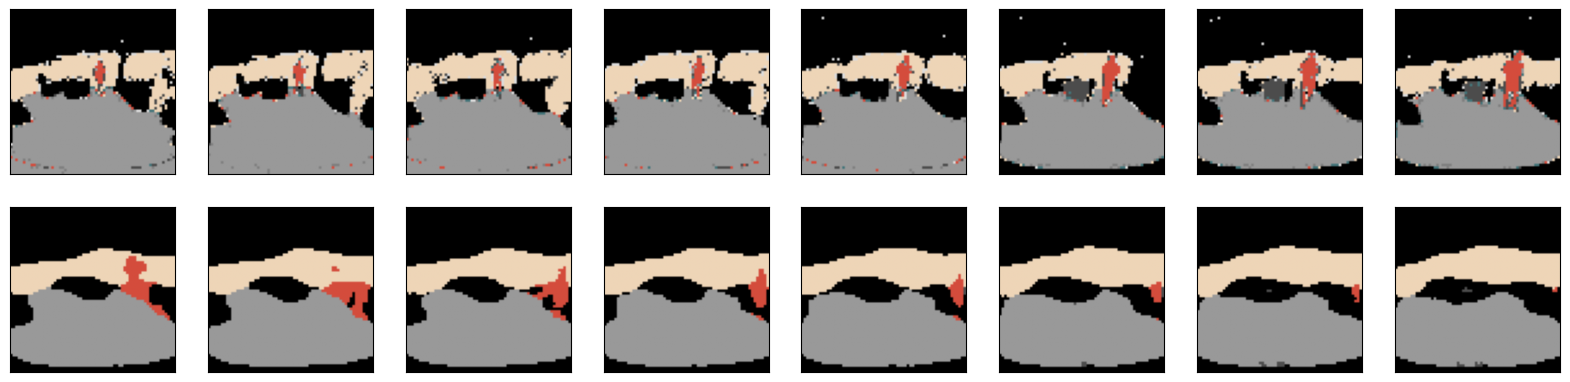

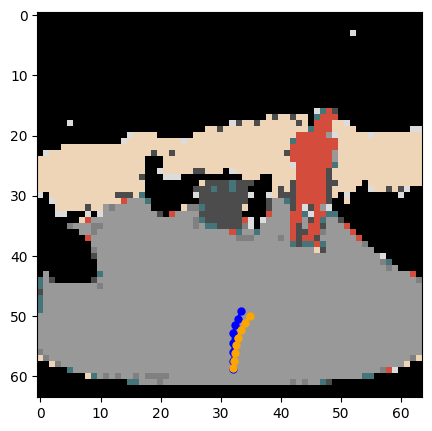

In [17]:
from videovae.utils import gray2color
print(dec_vid.shape)
fig = plt.figure(figsize=(20, 15))

dec_rgb = gray2color(dec_vid.squeeze().permute(1,0,2,3))
dec_rgb = torch.clamp(dec_rgb, 0,1)
print(dec_rgb.shape)
# Visualization of reconstructed intensity maps and robot actions    
for t in range(squence_length):
    im = torch.tensor(dec_rgb[t:t+1,:,:,:])
    im = im.squeeze().permute(1,2,0)
    
    if t==int(squence_length/2):
        map_x_pd = 60 - 10*torch.cumsum(torch.tensor(linear_pd[::int(squence_length/16)]), dim=0)*np.cos(np.pi/4)
        map_z_pd = 32 - torch.cumsum(torch.cumsum(torch.tensor(angle_pd[::int(squence_length/16)]), dim=0),dim=0)*np.cos(np.pi/4)
    ax = fig.add_subplot(6, int(squence_length/2), int(squence_length/2)+t+1, xticks=[], yticks=[])
    ax.imshow(im[:,:,:3])  

fig1 = plt.figure(figsize=(20, 5))
plt.plot(map_z.tolist(), map_x.tolist(), color='b',marker='o', linestyle='-',linewidth=2,markersize=5)
plt.plot(map_z_pd.tolist(), map_x_pd.tolist(), color='orange',marker='o', linestyle='-',linewidth=2,markersize=5)
im = torch.tensor(dec_rgb[half_seq_len-1,:,:,:]).squeeze().permute(1,2,0)
plt.imshow(im, 'gray')


### 4.3 Comparison between the predicted motion and ground truth

(-0.55, 0.55)

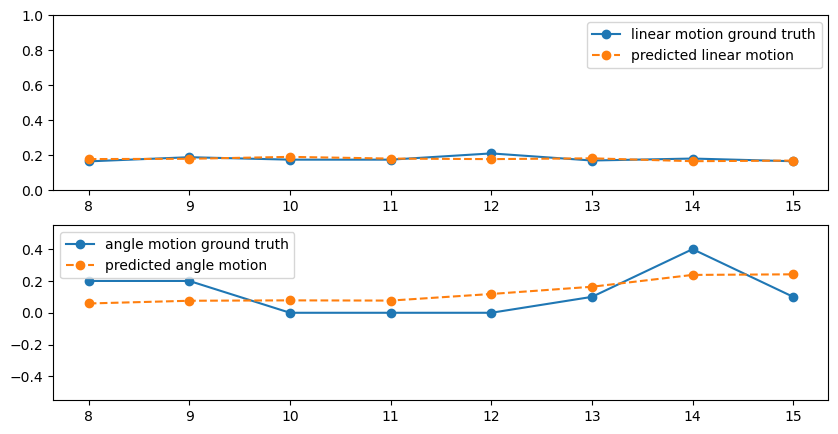

In [ ]:
fig = plt.figure(figsize=(10, 5))
x_list = list(range(half_seq_len,squence_length))
plt.subplot(2, 1, 1)
plt.plot(x_list,linear_gt, label='linear motion ground truth',marker='o', linestyle='-')
plt.plot(x_list,linear_pd, label='predicted linear motion', marker='o', linestyle='--')
plt.legend()
plt.ylim(0,1)

plt.subplot(2, 1, 2)
plt.plot(x_list,angle_gt, label='angle motion ground truth', marker='o', linestyle='-')
plt.plot(x_list,angle_pd, label='predicted angle motion', marker='o', linestyle='--')
plt.legend()
plt.ylim(-0.55, 0.55)
